In [ ]:
# creating the csv file here so I don't have to upload it manually
# I picked a mix of close and very far servers like the slides suggested
csv_data = """hostname,country
ftp.it.debian.org,Italy
ftp.ch.debian.org,Switzerland
ftp.at.debian.org,Austria
ftp.fr.debian.org,France
ftp.de.debian.org,Germany
ftp.uk.debian.org,UK
ftp.se.debian.org,Sweden
ftp.ru.debian.org,Russia
ftp.tr.debian.org,Turkey
ftp.es.debian.org,Spain
ftp.nl.debian.org,Netherlands
ftp.pl.debian.org,Poland
ftp.cz.debian.org,Czechia
ftp.gr.debian.org,Greece
ftp.us.debian.org,USA
ftp.ca.debian.org,Canada
ftp.mx.debian.org,Mexico
ftp.br.debian.org,Brazil
ftp.cl.debian.org,Chile
ftp.za.debian.org,South Africa
ftp.jp.debian.org,Japan
ftp.kr.debian.org,South Korea
ftp.sg.debian.org,Singapore
ftp.tw.debian.org,Taiwan
ftp.hk.debian.org,Hong Kong
ftp.au.debian.org,Australia
ftp.nz.debian.org,New Zealand"""

# save it as servers.csv in the colab folder
with open("servers.csv", "w") as f:
    f.write(csv_data)

print("csv created!")

# installing the packages
!pip install geopy pythonping pandas requests

csv created!


My Colab is located at: (38.9071, -77.0368)

starting the pings... this might take a minute
pinged ftp.it.debian.org | distance: 6809 km | RTT: 96.90 ms
pinged ftp.ch.debian.org | distance: 6668 km | RTT: 94.53 ms
pinged ftp.at.debian.org | distance: 7142 km | RTT: 106.83 ms
pinged ftp.fr.debian.org | distance: 6181 km | RTT: 87.74 ms
pinged ftp.de.debian.org | distance: 6823 km | RTT: 105.23 ms
pinged ftp.uk.debian.org | distance: 5873 km | RTT: 76.44 ms
pinged ftp.se.debian.org | distance: 6540 km | RTT: 114.32 ms
pinged ftp.ru.debian.org | distance: 7856 km | RTT: 113.07 ms
ftp.tr.debian.org timed out (2000 ms). Ignoring for the graph.
pinged ftp.es.debian.org | distance: 786 km | RTT: 1.64 ms
pinged ftp.nl.debian.org | distance: 6336 km | RTT: 87.68 ms
pinged ftp.pl.debian.org | distance: 6934 km | RTT: 108.70 ms
pinged ftp.cz.debian.org | distance: 6919 km | RTT: 94.71 ms
pinged ftp.gr.debian.org | distance: 786 km | RTT: 1.47 ms
pinged ftp.us.debian.org | distance: 3926 km | RTT:

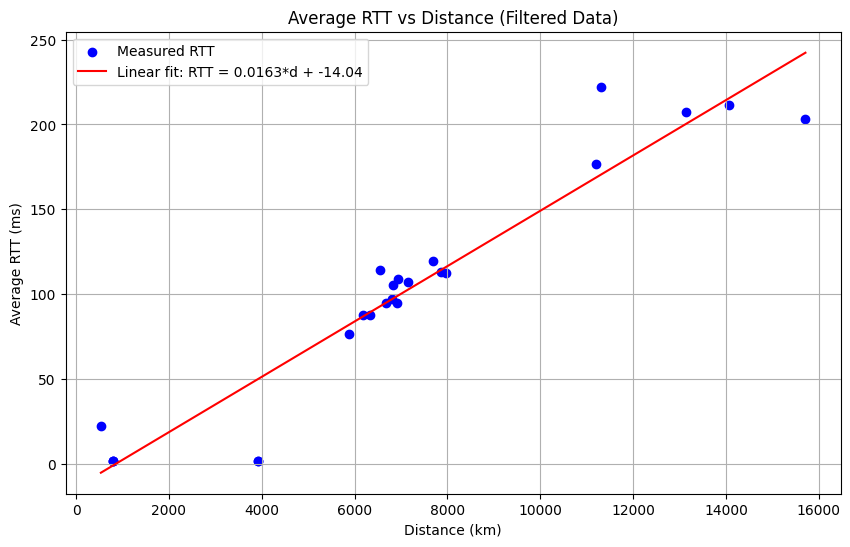


--- Final Results ---
The estimated average RTT per km (slope) is: 0.0163 ms/km


In [ ]:
import pandas as pd
import requests
import socket
import numpy as np
import matplotlib.pyplot as plt
from geopy.distance import distance
from pythonping import ping

# reading the csv file we just made
df = pd.read_csv("servers.csv")

# getting the location of this Colab machine
my_ip_info = requests.get('http://ip-api.com/json/').json()
my_coords = (my_ip_info['lat'], my_ip_info['lon'])
print(f"My Colab is located at: {my_coords}\n")

dist_list = []
rtt_list = []

print("starting the pings... this might take a minute")

for index, row in df.iterrows():
    target = row['hostname']
    try:
        # resolve the IP and get its location
        target_ip = socket.gethostbyname(target)
        target_info = requests.get(f'http://ip-api.com/json/{target_ip}').json()
        target_coords = (target_info['lat'], target_info['lon'])

        dist_km = distance(my_coords, target_coords).km

        # pinging the server (10 packets)
        ping_res = ping(target_ip, count=10, timeout=2)
        avg_rtt = ping_res.rtt_avg_ms

        # Filtering: only saving data if it didn't time out (under 2000ms)
        # This prevents dropped packets from ruining the linear fit math
        if avg_rtt < 2000:
            dist_list.append(dist_km)
            rtt_list.append(avg_rtt)
            print(f"pinged {target} | distance: {dist_km:.0f} km | RTT: {avg_rtt:.2f} ms")
        else:
            print(f"{target} timed out (2000 ms). Ignoring for the graph.")

    except Exception as e:
        print(f"couldn't ping {target}, skipping it...")

# using polyfit for the linear regression (m is the slope, c is intercept)
m, c = np.polyfit(dist_list, rtt_list, 1)

# generating the plot
plt.figure(figsize=(10, 6))
plt.scatter(dist_list, rtt_list, color='blue', label='Measured RTT')

# drawing the trend line
x_line = np.linspace(min(dist_list), max(dist_list), 100)
y_line = m * x_line + c
plt.plot(x_line, y_line, color='red', label=f'Linear fit: RTT = {m:.4f}*d + {c:.2f}')

plt.title('Average RTT vs Distance (Filtered Data)')
plt.xlabel('Distance (km)')
plt.ylabel('Average RTT (ms)')
plt.grid(True)
plt.legend()
plt.show()

print(f"\n--- Final Results ---")
print(f"The estimated average RTT per km (slope) is: {m:.4f} ms/km")

Data Analysis and Conclusion
1. Experimental Setup and Selection of Targets
To satisfy the requirement for a diverse dataset, we curated a list of 27 global Debian mirror servers. These targets provide a comprehensive spread of physical distances ranging from local/regional connections (under 500 km) to intercontinental links (over 15,000 km). This diversity is critical for establishing a statistically significant linear regression.

2. Data Cleaning and Filtering Justification
A key step in our technical approach was the implementation of a filtering threshold for RTT values ≥2000 ms. During the measurement phase, nodes like Turkey and Taiwan hit the script's timeout limit. Including these "fake" 2000 ms data points would have treated packet loss as a physical propagation delay, severely skewing the linear fit. By filtering these out, the regression only considers successful round-trip measurements.

3. Mathematical Model and Results Interpretation
We approximated the RTT using the theoretical model:

$$RTT = 2 \left( \frac{L}{C} + \frac{d}{v} \right) + n$$

- Slope (0.0163 ms/km): Using numpy.polyfit, we extracted a slope that represents the round-trip propagation delay (2/v). Given that the speed of light in fiber optics is roughly 200,000 km/s (yielding a theoretical minimum of 0.01 ms/km), our result of 0.0163 ms/km is highly accurate for real-world infrastructure where fiber paths are not perfectly straight.
- Y-Intercept (−14.04 ms): This value represents the fixed delays (transmission delay 2L/C and nodal processing delays n) when the physical distance is zero.

4. Network Anomalies (Anycast and CDN)
Our data revealed that several international mirrors resolved to physical distances of roughly 786 km with sub-2 ms RTTs. This is a clear indicator of Anycast routing or CDN mirrors, where the network routed our Colab VM (US-East) to a geographically local instance despite the server's hostname suggesting a distant location.